/Users/harryprasath/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Users/harryprasath/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Users/harryprasath/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/Users/harryprasath/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/harryprasath/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/harryprasath/Library/Python/3.9/lib/python/site-packages/sklearn/utils/extmath.py:203: RuntimeWarning: invalid value 

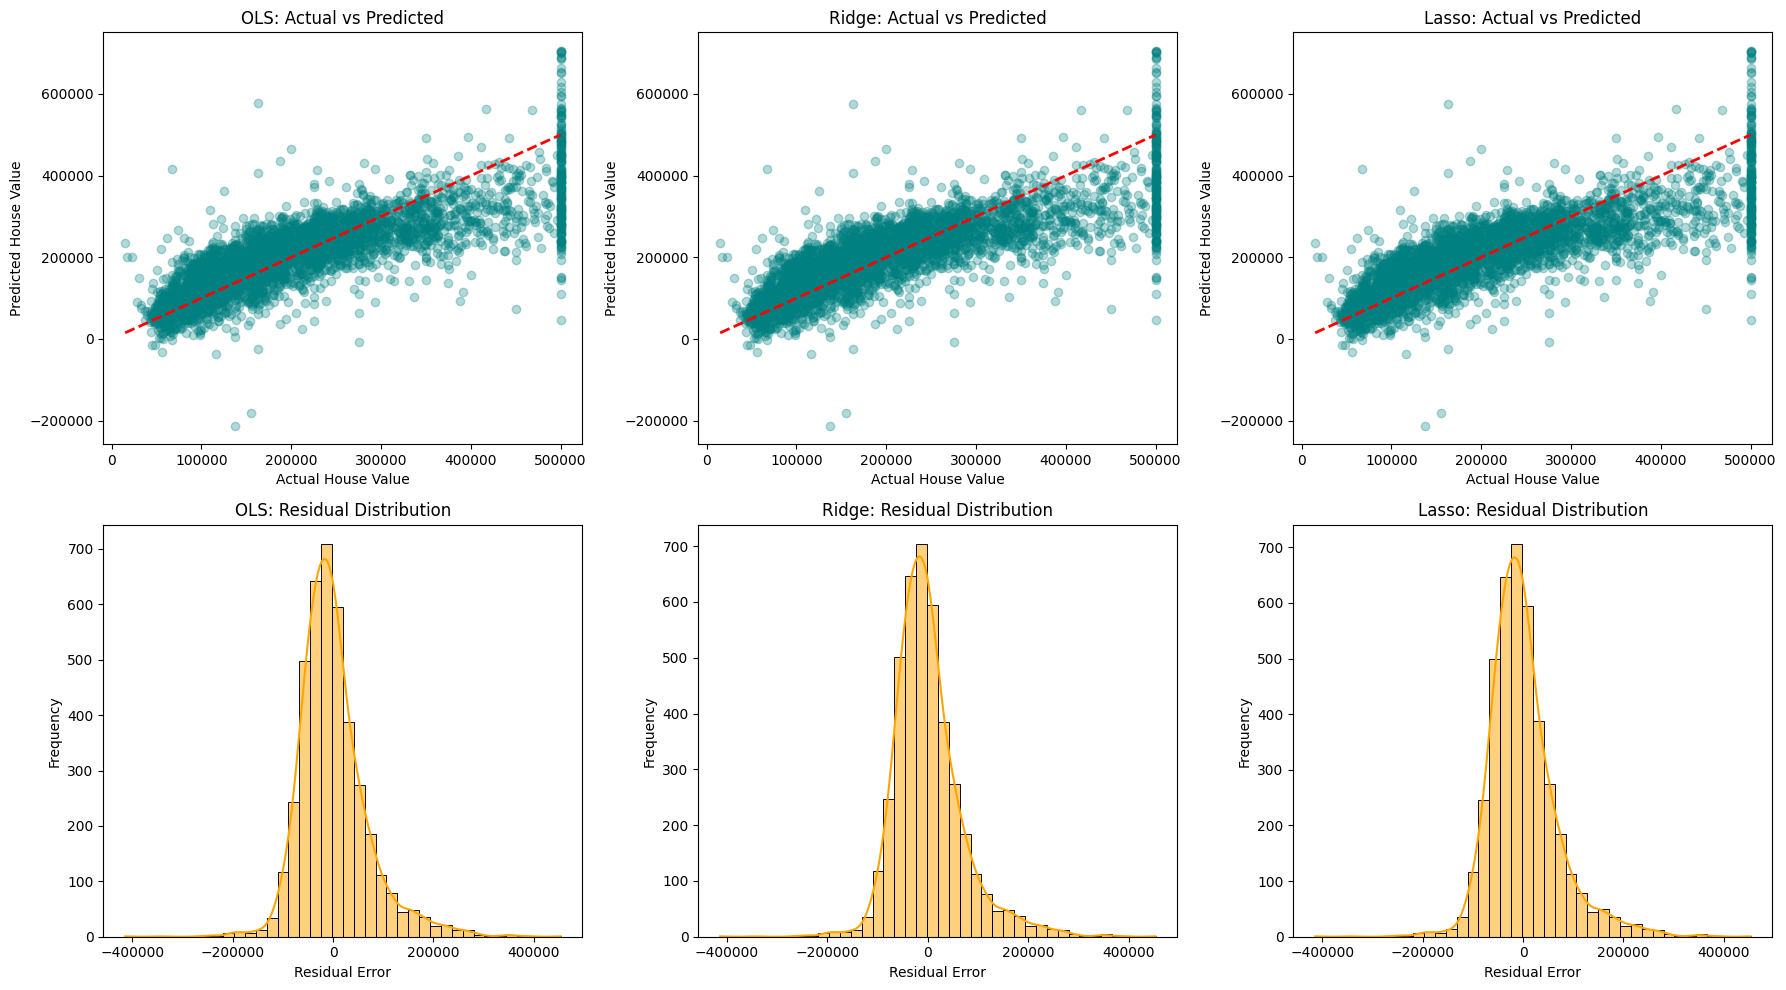

In [16]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Load the dataset from the provided raw URL
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
df = pd.read_csv(url)

# 2. Engineer interaction features to improve model performance
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

# 3. Separate features (X) and target (y), and Split 80/20
X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Standardize continuous variables and encode categorical attributes
numeric_features = X.select_dtypes(include=[np.number]).columns
categorical_features = ["ocean_proximity"]

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Apply transformations (This creates X_train_scaled!)
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

# 5. Train Models
# Ordinary Least Squares (OLS)
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)
y_pred_ols = ols.predict(X_test_scaled)

# Ridge Regression (L2) with GridSearchCV
ridge_params = {'alpha': [0.1, 1.0, 10.0, 50.0, 100.0]}
ridge_grid = GridSearchCV(Ridge(random_state=42), ridge_params, cv=5, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train_scaled, y_train)
best_ridge = ridge_grid.best_estimator_
y_pred_ridge = best_ridge.predict(X_test_scaled)

# Lasso Regression (L1) with GridSearchCV
lasso_params = {'alpha': [1.0, 10.0, 50.0, 100.0, 500.0]}
lasso_grid = GridSearchCV(Lasso(random_state=42, max_iter=10000), lasso_params, cv=5, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train_scaled, y_train)
best_lasso = lasso_grid.best_estimator_
y_pred_lasso = best_lasso.predict(X_test_scaled)

# 6. Plotting
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
models = [('OLS', y_pred_ols), ('Ridge', y_pred_ridge), ('Lasso', y_pred_lasso)]

for i, (name, y_pred) in enumerate(models):
    # Predicted vs Actual Scatter
    axes[0, i].scatter(y_test, y_pred, alpha=0.3, color='teal')
    axes[0, i].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
    axes[0, i].set_title(f'{name}: Actual vs Predicted')
    axes[0, i].set_xlabel('Actual House Value')
    axes[0, i].set_ylabel('Predicted House Value')
    
    # Residual Distribution
    residuals = y_test - y_pred
    sns.histplot(residuals, kde=True, ax=axes[1, i], color='orange', bins=40)
    axes[1, i].set_title(f'{name}: Residual Distribution')
    axes[1, i].set_xlabel('Residual Error')
    axes[1, i].set_ylabel('Frequency')

plt.tight_layout()
plt.show()